# 08 · Свежая популярность, признаки ранкера и разные недели

После первого сравнения осталось два вопроса. Популярность считалась за всю историю, хотя у CatBoost важным признаком оказалась популярность последней недели. Кроме того, качество было проверено на одном финальном периоде.

Здесь сравниваю свежую популярность с исходной, разбираю вклад групп признаков ранкера и повторяю оценку на трёх неделях. Состав кандидатов, порог просмотра и метрики остаются прежними.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports" / "study"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(
    {
        "figure.figsize": (9, 4),
        "font.size": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
metrics = pd.read_csv(REPORTS / "metrics.csv")
validation = pd.read_csv(REPORTS / "validation.csv")
metric_columns = ["MAP@10", "Recall@10", "NDCG@10", "HitRate@10", "Coverage"]
final = metrics.loc[metrics.test_start.eq("2021-08-16")].set_index("model")
final_validation = validation.loc[validation.test_start.eq("2021-08-16")]

## Популярность за последнее время

Проверяю окна 7, 14 и 30 дней. В каждом варианте использую тот же исторический каталог и исключаю все прежние просмотры. Если число свежих зрителей одинаковое, выше ставлю объект с большей популярностью за всю историю, затем с меньшим ID.

Окно выбирается на предыдущей неделе. На финальном периоде 16–22 августа оценивается только выбранный вариант.

,model,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage
12,Popularity,0.1351,0.2556,0.1751,0.3311,0.0026
13,RecentPopularity_7,0.1468,0.2808,0.1907,0.3659,0.0024
14,RecentPopularity_14,0.1460,0.2803,0.1898,0.3658,0.0026
15,RecentPopularity_30,0.1385,0.2693,0.1813,0.3514,0.0024


,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage
model,,,,,
Popularity,0.1215,0.2366,0.1598,0.3127,0.0027
RecentPopularity_7,0.1319,0.2690,0.1762,0.3551,0.0026
CatBoost_full,0.1456,0.2832,0.1920,0.3814,0.1438


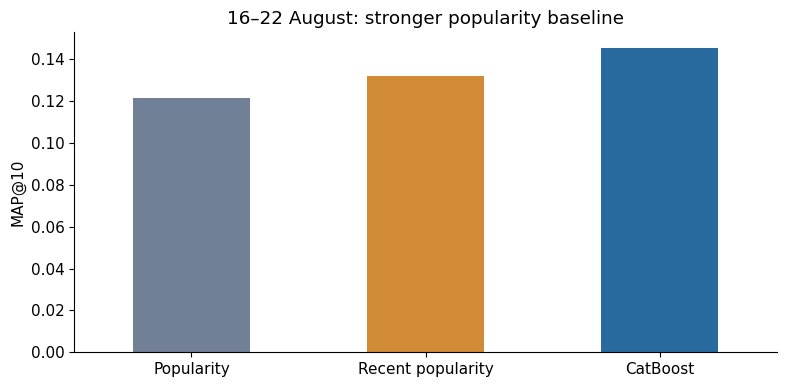

In [2]:
popularity_grid = final_validation.loc[
    final_validation.model.str.startswith(("Popularity", "RecentPopularity"))
]
display(popularity_grid[["model"] + metric_columns].round(4))
recent_name = next(name for name in final.index if name.startswith("RecentPopularity"))
comparison = final.loc[["Popularity", recent_name, "CatBoost_full"], metric_columns]
display(comparison.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
comparison["MAP@10"].rename(
    index={recent_name: "Recent popularity", "CatBoost_full": "CatBoost"}
).plot.bar(ax=ax, rot=0, color=["#718096", "#d18a35", "#286a9d"])
ax.set(title="16–22 August: stronger popularity baseline", ylabel="MAP@10", xlabel="")
ax.set_ylim(bottom=0)
plt.tight_layout()
fig.savefig(FIGURES / "recent_popularity.png", dpi=160)
plt.show()

На Validation лучшее окно — **7 дней**. На Test свежая популярность получила MAP@10 **0.1319** против **0.1215** у исходной. CatBoost с **0.1456** остаётся выше: прирост относительно более сильного baseline составляет **10,3%**.

Это уточняет первый результат проекта. Разница в 19,8% с популярностью за всю историю была реальной, но часть преимущества объясняется тем, что ранкер учитывает недавний спрос. После обновления baseline разница стала меньше.

## Что добавляют признаки CatBoost

Сравниваю три набора:

- активность пользователя, давность просмотра, общая и свежая популярность;
- те же признаки вместе со scores и рангами моделей;
- дополнительно год выпуска, возрастной рейтинг и тип контента.

Для всех вариантов одинаковые кандидаты, обучающие группы и параметры CatBoost. Параметры выбраны для полного набора на Validation. Таким образом меняется только набор признаков. Даже в первом варианте пул кандидатов уже использует Content-Based; этот опыт проверяет признаки ранжирования, а не пользу метаданных во всей системе.

,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage
model,,,,,
Activity + popularity,0.1319,0.2618,0.1748,0.3514,0.0252
+ model scores,0.1444,0.2827,0.1910,0.3810,0.1543
+ item metadata,0.1456,0.2832,0.1920,0.3814,0.1438


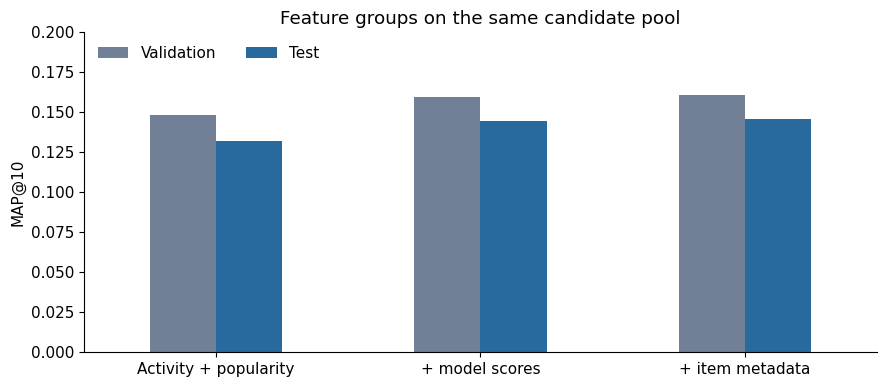

In [3]:
group_names = {
    "CatBoost_activity": "Activity + popularity",
    "CatBoost_scores": "+ model scores",
    "CatBoost_full": "+ item metadata",
}
feature_comparison = final.loc[list(group_names), metric_columns]
display(feature_comparison.rename(index=group_names).round(4))
validation_rankers = final_validation.loc[
    final_validation.model.str.startswith("CatBoost")
]
validation_scores = validation_rankers.groupby("model")["MAP@10"].max()
plot_data = pd.DataFrame(
    {
        "Validation": validation_scores.reindex(group_names),
        "Test": feature_comparison["MAP@10"],
    }
).rename(index=group_names)
fig, ax = plt.subplots(figsize=(9, 4))
plot_data.plot.bar(ax=ax, rot=0, color=["#718096", "#286a9d"])
ax.set(title="Feature groups on the same candidate pool", ylabel="MAP@10", xlabel="")
ax.set_ylim(0, 0.20)
ax.legend(ncol=2, loc="upper left", frameon=False)
plt.tight_layout()
fig.savefig(FIGURES / "feature_groups.png", dpi=160)
plt.show()

Популярность и активность дали **0.1319** — практически столько же, сколько свежая популярность. После добавления scores и рангов моделей MAP@10 вырос до **0.1444**. Полный набор получил **0.1456**: три свойства контента добавили ещё около **0.0012**. На Validation порядок вариантов такой же.

В этом опыте основная прибавка связана с сигналами рекомендательных моделей. Метаданные дали небольшое улучшение MAP@10, при этом покрытие уменьшилось с 15,43% до 14,38%. По основной метрике сохраняю полный вариант, выбранный на Validation. Подбирать параметры заново после этого сравнения не стал.

## Три временных среза

На каждой оценочной неделе выбор окна популярности и параметров CatBoost делается заново по предыдущей неделе. Для обучения ранкера используется ещё более ранняя неделя. После выбора параметров ранкер обучается на двух прошлых окнах.

| Оценка | Выбор параметров | Первое окно обучения ранкера |
|---|---|---|
| 2–8 августа | 26 июля – 1 августа | 19–25 июля |
| 9–15 августа | 2–8 августа | 26 июля – 1 августа |
| 16–22 августа | 9–15 августа | 2–8 августа |

Это историческое сравнение на полной доступной истории. Августовские периоды уже использовались в проекте, поэтому я рассматриваю результат как проверку поведения на разных неделях, а не как оценку на новом неизвестном датасете.

,test_start,method,recent_window_days,MAP@10,Recall@10,NDCG@10,HitRate@10,Coverage
0,2021-08-02,Popularity,14,0.1484,0.2793,0.1918,0.3604,0.0026
1,2021-08-02,Recent popularity,14,0.1534,0.2976,0.2005,0.3851,0.0024
2,2021-08-02,CatBoost,14,0.1672,0.3243,0.2194,0.4254,0.1439
3,2021-08-09,Popularity,7,0.1351,0.2556,0.1751,0.3311,0.0026
4,2021-08-09,Recent popularity,7,0.1468,0.2808,0.1907,0.3659,0.0024
5,2021-08-09,CatBoost,7,0.1607,0.2983,0.2076,0.3957,0.1323
6,2021-08-16,Popularity,7,0.1215,0.2366,0.1598,0.3127,0.0027
7,2021-08-16,Recent popularity,7,0.1319,0.2690,0.1762,0.3551,0.0026
10,2021-08-16,CatBoost,7,0.1456,0.2832,0.1920,0.3814,0.1438


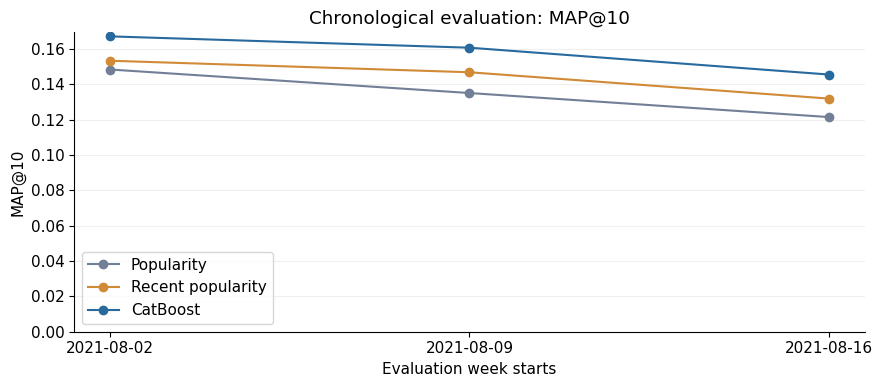

In [4]:
rolling = metrics.loc[
    metrics.model.isin(["Popularity", "CatBoost_full"])
    | metrics.model.str.startswith("RecentPopularity")
].copy()
rolling["method"] = rolling.model.map(
    lambda name: "Recent popularity"
    if name.startswith("RecentPopularity")
    else name.replace("_full", "")
)
display(
    rolling[["test_start", "method", "recent_window_days"] + metric_columns].round(4)
)
weekly_scores = rolling.pivot(index="test_start", columns="method", values="MAP@10")
fig, ax = plt.subplots(figsize=(9, 4))
for model, color in [
    ("Popularity", "#718096"),
    ("Recent popularity", "#d18a35"),
    ("CatBoost", "#286a9d"),
]:
    ax.plot(
        weekly_scores.index, weekly_scores[model], marker="o", label=model, color=color
    )
ax.set(
    title="Chronological evaluation: MAP@10",
    xlabel="Evaluation week starts",
    ylabel="MAP@10",
)
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
fig.savefig(FIGURES / "rolling_evaluation.png", dpi=160)
plt.show()

CatBoost выше обоих вариантов популярности на всех трёх неделях. Прирост относительно выбранной свежей популярности — **9,0%, 9,5% и 10,3%** соответственно. Для первого среза Validation выбрала окно 14 дней, для следующих — 7 дней.

При этом абсолютные метрики снижаются у всех трёх моделей. Полнота пула кандидатов тоже уменьшается: **43,6% → 41,8% → 39,8%**. По одной неделе эту разницу между периодами было бы не видно. Результат показывает преимущество ранкера на этих срезах, но не даёт оснований ожидать постоянного значения метрики.

## Решение после дополнительных экспериментов

Основным решением оставляю полный CatBoost, выбранный на Validation. Свежая популярность остаётся простым и достаточно сильным вариантом для сравнения. Добавление scores и рангов моделей оправдано полученным приростом; три свойства контента дали меньшую, но положительную прибавку MAP@10. 

Полный запуск дополнительных экспериментов: `python -m kion_recsys.study`. Значения в таблицах загружаются из `reports/study/`, а кэш кандидатов сохраняется отдельно и не входит в Git.